# AI 최적화 & 엔지니어링

## 1. 전이학습과 딥러닝 경량화  
  
### 1-1. 전이학습  
  
#### 딥러닝 모델의 한계  
- 데이터 부족: 학습할 사례가 적은 경우
- 과적합: 데이터 부족하면 한정된 데이터에 지나치게 맞추는 과적합 발생
- 시간, 비용: 처음부터 학습해야 하므로 학습 시에 많은 시간과 비용 소모
  
### 1-2. 전이학습의 정의  
  
#### 전이학습  
> 모델이 사전 학습을 통해 배운 능력을 활용해 새로운 작업을 학습하는 것  
  
- 모델 사전 학습하기: 유사한 목적으로 학습된 모델을 가져오기
- 기존 모델에서 사용할 부분과 교체할 부분 파악
- 교체할 부분 새로 학습시키기
- 파인튜닝: 모델의 가중치 조정
  
*모델 전체를 처음부터 학습 시킬 필요 X*  
  
#### 전이학습의 4가지 핵심 용어  
  
- Source: 기존에 학습한 문제
- Target: 새롭게 해결할 문제
- Domain: 사용한 데이터의 특성
- Task: 수행하려는 작업
  
### 1-3. 전이학습의 분류  
  
#### 도메인과 태스크에 따른 분류  
  
- 귀납적: 기존에 학습했던 모델의 능력을 바탕으로 정답 레이블이 존재하는 사진 여러 장을 학습
- 변환적: Source와 Target의 도메인은 다르지만, 하는 작업 자체는 동일한 경우
- 비지도: Source와 Target 모두 정답 레이블이 없는 비지도 학습
  
#### 전이 대상에 따른 분류  
  
- 전이 대상: 새 작업을 배울 때 기존 모델에서 가져오는 대상
    - 인스턴스 기반: 기존 데이터 일부
    - 특성 기반: 데이터 나타내는 특징 표현
    - 파라미터 기반: 기존 모델의 학습된 가중치, 편향
    - 관계 기반: 데이터나 개체 사이의 관계 패턴
  
### 1-4. Pre-training & Fine-tuning  
  
#### 전통적인 전이학습  
  
- 이미지 분야: 정답 레이블이 붙은 대규모 이미지 데이터로 CNN 사전 학습
    - 윤곽, 질감, 모양 같은 특징을 찾는 법 학습 -> 그 능력이 담긴 가중치를 이용
- 언어 분야: 정적 단어 임베딩
    - 단어가 어떤 다른 단어와 함께 쓰이는지 살펴보고, 각 단어를 나타내는 숫자 벡터 학습 -> 감정 분석, 스팸 분류 모델의 입력으로 사용
  
#### 트랜스포머 이후의 전이학습  
  
- 이미지 분야: 대규모 이미질 사전 학습한 모델을 여러 작업의 출발점으로 사용
    - 자기지도학습: 이미지 일부를 가리고 복원하는 과정에서 모델이 이미지의 특징을 파악하는 법을 학습
    - 이미지, 텍스트 공동 학습: 사진과 그 사진을 설명하는 문장을 함께 보여주며, 이미지와 문장이 얼마나 잘 맞는 지 판단하는 법을 학습
- 언어 분야: 대규모 말뭉치로 모델을 사전 학습해 문맥을 반영하는 표현을 얻음
    - BERT로 분류하는 경우: 문장의 특징을 받아 분류층을 붙임. 라벨이 있는 문장으로 분류층을 학습하고 필요에 따라 BERT 본체도 함께 파인튜닝
    - 생성형 LLM으로 답변 만드는 경우: 기존 문장 생성 구조 활용. 질문과 모범 답변을 짝지은 데이터로 추가학습
  
#### Foundation Model  
  
> 여러 작업에 활용할 수 있도록 방대한 데이터로 사전 학습한 기반 모델  
  
- 하나의 모델에서 시작하여 원하는 작업에 따라 추가 학습을 진행하여 여러 특화 모델을 만들 수 있고, 시작점이 된 모델을 Foundation model이라고 함
  
#### Fine-tuning  
  
> 사전 학습된 모델을 새 작업의 데이터로 추가 학습하고, 기존 모델의 가중치 일부 또는 전체를 조정  
  
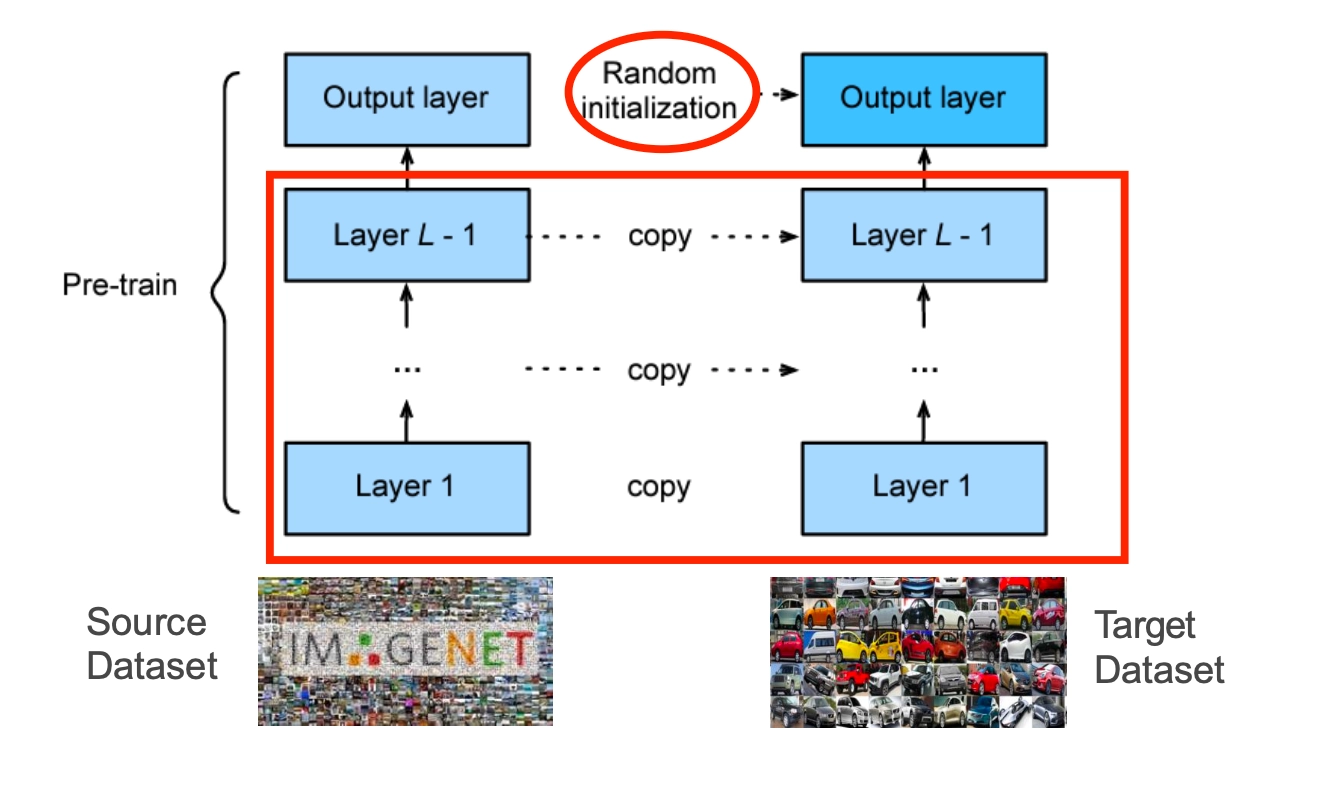  
  
- 처음부터 새로운 모델을 학습시키는 대신, 기존 모델이 가진 특징 추출 능력을 활용
- 기존 모델의 마지막 분류층을 새로운 모델의 새로운 분류층으로 교체
    - 특징 추출 -> 예측 -> 오차 계산 -> 가중치 업데이트
    - 모델의 모든 가중치를 반드시 업데이트할 필요는 없음
  
#### Fine-tuning 방법  
  
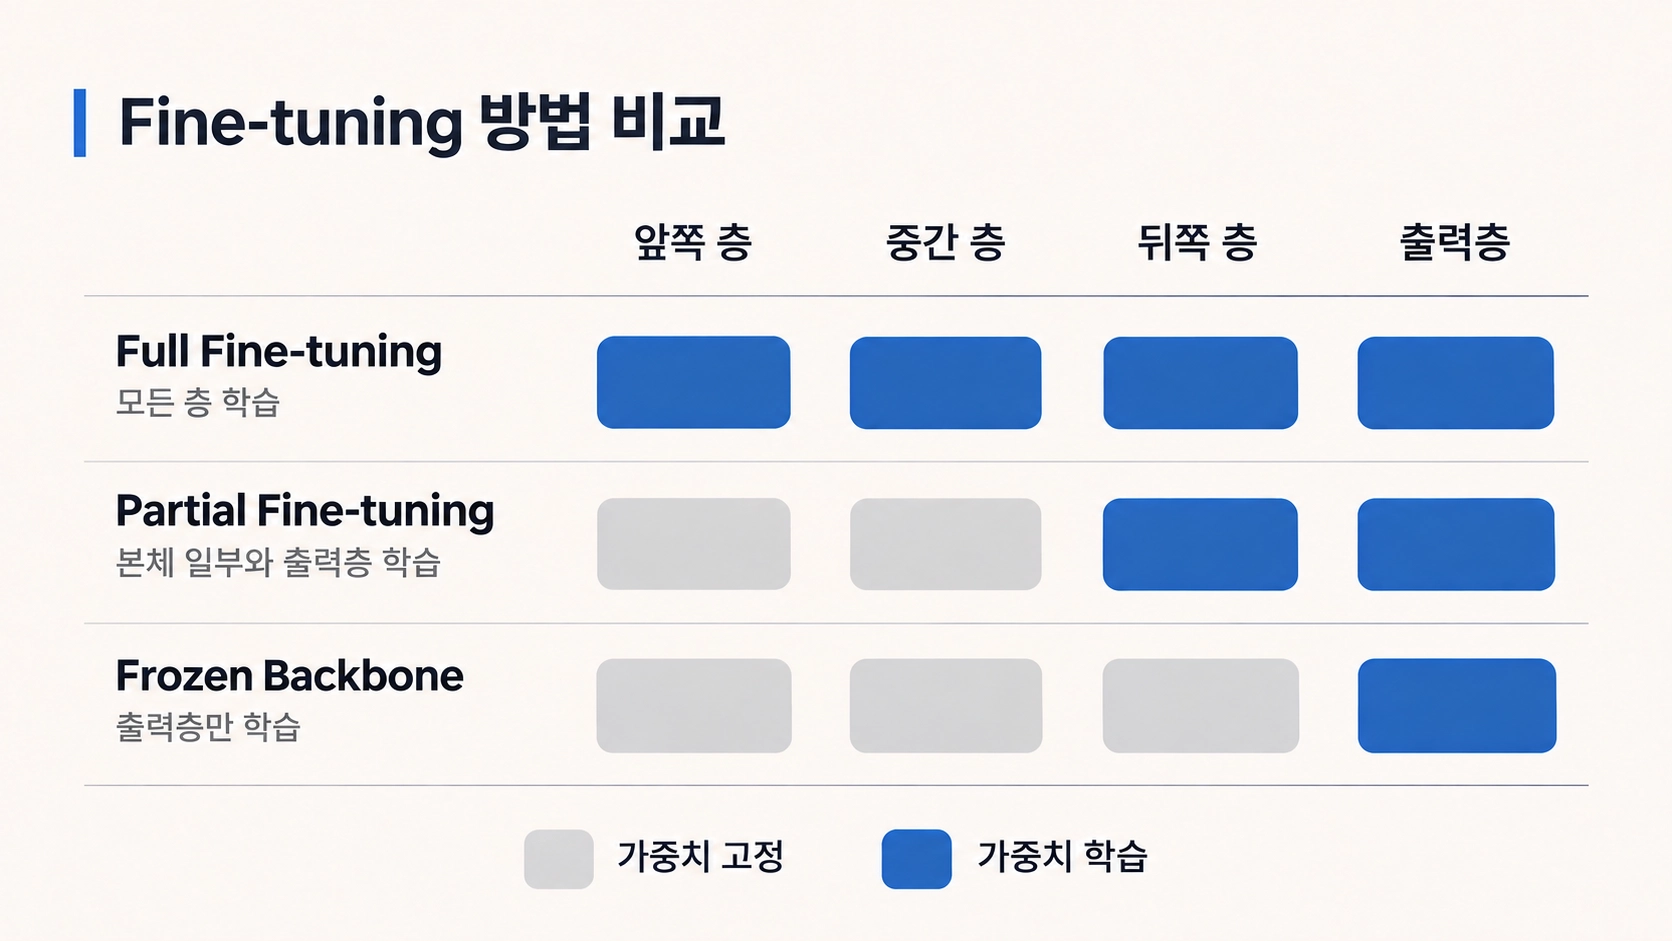  
  
- Full Fine-tuning: 모델의 모든 가중치를 업데이트
- Partial Fine-tuning: 사전 학습된 모델의 일부 층을 고정하고, 나머지 층의 가중치만 업데이트
- Frozen Backbone: 새 분류층만 학습
  
### 1-5. Fine-tuning의 한계를 넘어서  
  
#### PEFT (Parameter-Efficient Fine-tuning)  
  
> 사전 학습 모델의 가중치 대부분을 고정하고 새 작업에 필요한 최소한의 파라미터만 학습하는 방법  
  
#### PEFT 구현 방법  
  
- LoRA (Low-Rank Adaption): 기존 모델에 더할 수정분을 작은 두 행렬로 학습  
    - Low-Rank: 수정 행렬을 작은 행렬의 곱으로 표현할 수 있다는 뜻 (학습 과정에서 작은 행렬의 가중치를 조정 가능)
    - Adaptation: 이 보정으로 모델을 새 작업에 맞춤
- Adapter: 기존 모델 중간에 작은 신경망을 넣는 방식 (추가된 신경망의 가중치만 학습)
- Prompt tuning: 모델 입력에 학습 가능한 숫자 벡터를 붙이는 방식 (학습용 숫자 벡터를 붙이고 이 학습용 벡터를 조정하며 모델 분류에 용이한 특징 뽑아냄)  
  
#### Zero-shot & Few-shot  
  
- Few-shot: 몇 개의 예시를 프롬프트에 제공하는 방식
- Zero-shot: 원하는 작업을 예시 없이 지시만 주는 방식
  
### 1-6. 전이학습의 한계  
  
- Negative Transfer: 전이학습 적용 후에 새 작업에서의 성능이 낮은 경우
- Catastrophic Forgetting: 새 데이터를 학습하며 기존 능력이 약해지는 경우
- Bias Transfer: 사전 학습에서 얻은 편향이 새 작업에서도 이어짐
- Transferability 측정의 어려움: 사전 학습 모델이 배운 지식이 새 작업에 얼마나 잘 활용될 수 있는지 측정 어려움
  
### 1-7. 전이학습 사용 사례  
  
- 분야별 사례
    - CV: 의료 영상, X-ray에서 질환 분류
    - NLP: 법률 문서, 계약서 조항 분류
  
### 1-8. 딥러닝 모델 경량화  
  
- 가지치기: 모델에서 예측에 미치는 영향이 작다고 판단한 부분 제거 (비구조적 가지치기/구조적 가지치기)
- 양자화: 모델이 쓰는 숫자를 덜 정밀하게 표현하여 저장공간 줄임
- 지식 증류: 큰 모델을 Teacher 모델로 두고 작은 Student 모델이 정답과 Teacher 모델의 출력 분포를 함께 학습하도록 하는 방법
- 모델 구조 경량화: 모델을 설계할 때부터 같은 작업을 더 적은 계산으로 수행할 수 있는 구조를 선택  

## 2. AI Alignment  
  
### 2-1. AI Alignment  
  
- 기존 한계: 사실과 다른 문장을 만들거나 사전 학습 데이터에서 생성된 편향이 드러나기도 함
- AI Alignment: 어떤 답변이 사람에게 바람직한 지 정렬하는 기준을 정한 후, 모델이 그 기준에 맞게끔 답하도록 조정하는 과정
- 정렬 기준: Helpful, Honest, Harmless
- 관점
    - Outer Alignment: *목표를 제대로 설정했는가?* (보상 해킹이 발생하지 않는지 확인)
    - Inner Alignment: *모델이 실제로 무엇을 배웠는가?* (기만적 정렬이 발생하지 않아야 함)  
- 정렬을 오렵게 만드는 요인
    - 가치 정렬의 모호성: 사람마다 가치관이 달라서 모두가 동의하는 기준 만들기 어려움
    - 감독: 사람이 직접 확인할 수 있는 범위에는 한계가 존재  
  
### 2-2. RLHF  
  
#### RLHF (Reinforcement Learning from Human Feedback)  
  
> 사람들의 피드백을 학습에 사용하여, 사람들이 선호하는 답변에 높은 점수를 주는 방식  
  
#### 고전적 RLFT 파이프라인: SFT → Reward Model → RL  
  
- SFT (Supervised Fine-tuning): 사람이 작성한 모범 답변을 언어 모델에 보여주고 학습하는 단계
- Reward Model: 사람이 선호한 답변에 더 높은 점수를 주는 보상 모델을 학습하는 단계
- RL (Reinforcement Learning): 모델이 생성한 답변을 학습된 Reward Model이 채점하고, 높은 보상을 받는 답변을 더 자주 생성하도록 조정  
  
#### 부작용  
  
- Reward Hacking: 좋은 답변보단 높은 보상 점수 받도록 학습
- Sycophancy: 모델이 사실이나 근거보다는 사용자 생각에 무조건적으로 동의

## 3. 프롬프트 엔지니어링  
  
### 3-1. 프롬프트 엔지니어링  
  
#### 프롬프트 엔지니어링  
  
- 파라미터를 바꾸지 않고, 질문하는 방법을 바꿈
- AI가 더 좋은 답을 내놓도록 입력(프롬프트)을 설계하는 기술
  
### 3-2. 주요 기법  
  
#### Zero-shot & Few-shot  
  
- Zero-shot : 예시 없이 지시만 주는 방식
- Few-shot : 입력과 출력의 예시를 몇 개 보여준 뒤 같은 형식으로 답하게 하는 방식  
  
#### Chain-of-Thought (CoT)  
  
- 중간 풀이 과정을 단계별로 쓰게하는 방식
  
#### Role Prompting  
  
- 모델에게 역할을 부여해서 답의 관점, 말투, 설명 수준을 조절  
  
#### Instruction Prompting  
  
- 원하는 것을 구체적으로 적어서 지시하는 방식
- 답의 형식, 길이, 누구를 위한 답인지, 꼭 들어가야 할 내용을 정해서 알려줌
  
#### Self-Consistency  
  
- 같은 문제를 여러 번 풀게 하고, 가장 많이 나온 최종 답을 선택하는 방식  
  
### 3-3. 프롬프트 엔지니어링의 한계  
  
- Prompt Injection: 어디까지가 시스템의 지시이고, 사용자 입력인지 명확하게 구분되지 않음
- Hallucination: 사실이 아닌 내용을 그럴듯하게 만들어내는 문제
- 모델 의존성: 같은 프롬프트도 모델이나 버전이 바뀌면 결과가 달라짐
- 성능 한계: 모델이 원래 못하는 일은 프롬프트로 해결되지 않음


## 4. 하네스 엔지니어링  
  
### 4-1. 프롬프트 다음의 질문  
  
#### 하네스  
  
- Agent: 도구를 쓰며 여러 단계를 스스로 진행하는 AI
    - 모델 본체: LLM
    - 모델이 일하도록 둘러싼 시스템: 하네스
- 하네스: 지시/컨텍스트, 도구 인터페이스, 실행 환경, 상태/메모리, 관측/피드백, 권한/가드레일이 포함  
    - 모델이 실제로 일을 할 수 있도록 필요한 도구와 정보, 규칙을 갖춰주는 것
  
### 4-2. 하네스의 구성 요소  
  
- 지시/컨텍스트: 모델이 무엇을 보고 시작하나
- 도구 인터페이스: 모델이 무엇을, 어떤 형식으로 할 수 있나
- 실행 환경: 행동이 실제로 어디서 실행되나
- 상태/메모리: 지금까지 한 일을 어떻게 기억하나
- 관측/피드백: 행동의 결과를 어떻게 돌려받나
- 권한/가드레일: 무엇은 하면 안 되나
  
### 4-3. 실패는 어디서 오는가  
  
#### 인터페이스  
  
- 에이전트가 실패해도 추론력만 의심해서는 안됨
- 인터페이스: 에이전트가 무엇을 볼 수 있고, 어떤 행동을 어떤 형식으로 할 수 있는지를 정한 인터페이스에 따라서도 성능과 행동이 크게 달라짐 (SWE-agent 연구)  
  
#### 증상과 수정할 곳  
  
> 증상을 보고 수정할 곳을 찾아서 수정해야 함  
  
- ex. 엉뚱한 도구를 부름 → 도구 인터페이스를 수정


## 5. 루프 엔지니어링  
  
### 5-1. 루프  
  
#### 사람이 하던 반복을 시스템으로  
  
- 루프: 사람이 답을 읽고 틀린 곳을 찾고 수정 요청을 하던 반복을 시스템이 하도록 만든 것
- 루프 엔지니어링: 모델이 행동을 제안하고, 시스템이 행동을 실행하고, 그 결과를 다시 모델에게 돌려주는 과정을 종료 조건까지 반복하도록 설계
  
- 과정
    1. 관측: 지금 상황을 봄
    2. 판단: 다음 행동을 정함
    3. 행동: 도구를 실행함
    4. 검증: 결과가 목표에 맞는지 확인함
  
#### 공간에서 시간으로  
  
- 하네스: 모델이 일하는 공간과 조건을 설계
- 루프: 그 요소들이 시간에 따라 어떤 순서로 반복되는지를 설계  
  
#### ReAct  
  
- ReAct (Reasoning + Acting): 생각과 행동을 번갈아 함
    - Thought: 지금 무엇이 필요한지 판단
    - Action: 검색, 도구 호출 같은 행동을 실행
    - Observation: 행동의 결과를 보고 다음 생각에 반영
  
### 5-2. 루프의 구성 요소  
  
- 목표: 무엇을 끝내려 하나
- 트리거: 루프가 언제 시작되나
- 관측과 행동: 매 반복에서 무엇을 보고 무엇을 하나
- 정상 종료 조건: 성공해서 멈추는 조건
- 안전 상항: 위험해서 멈추는 조건
- 실패/승인 처리: 막혔을 때, 위험할 때 어떻게 하나
  
### 5-3. 통제  
  
#### 루프에서 증폭되는 실패  
  
- 무한 반복
- 토큰/비용 폭주
- 컨텍스트 누적에 따른 품질 저하
- 같은 부작용의 반복
- 되돌리기 어려운 행동
  
#### 통제 장치  
  
- 반복, 시간, 비용 상한
- 테스트와 완료 조건
- 중복 실행 방지
- 체크포인트와 롤백
- 위험도에 따른 행동 분리